# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** CHATBOT RUMO · **Tema:** Chatbot sobre mobilidade acadêmica

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [15]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/SEU_USUARIO/SEU_REPOSITORIO.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [16]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

In [17]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])
print("Limiar de confiança do tema:", config.limiar_tema)
pd.DataFrame(
    [(i.nome, i.descricao, i.resposta[:70] + "...") for i in config.intencoes.values()],
    columns=["intenção", "descrição", "resposta (início)"],
)

Grupo: chatbot RUMO | Tema: Chatbot de mobilidade acadêmica e intercâmbio da UFMS
Limiar de confiança do tema: 0.0


,intenção,descrição,resposta (início)
0,proficiencia,Exigência de idioma e certificados aceitos,"Depende do destino: cada vaga define o idioma e o nível, geralmente B1..."
1,custos_auxilio,"Custo do intercâmbio, bolsas e auxílios financeiros","Em geral não há mensalidade, mas passagem, visto, seguro, moradia e al..."
2,destino_parcerias,Universidades conveniadas e países disponíveis,As universidades parceiras e as vagas estão no Quadro de Oportunidades...
3,mobilidade_nacional,Cursar um período em outra universidade brasileira,Pelo Programa Andifes você pode cursar até dois semestres em outra fed...
4,documentos_viagem,"Visto, passaporte, seguro saúde, vacinas e exigências de entrada em outros p...","Você vai precisar de passaporte, visto (se o país exigir) e seguro saú..."
5,inscricao,"Editais abertos, prazos e formas de me candidatar","A inscrição é feita pelo SIGProj (sigproj.ufms.br), escolhendo uma uni..."
6,requisitos,"Requisitos acadêmicos para participação (CRA, semestre, vínculo)","Na graduação, é preciso estar matriculado, ter cursado entre 20% e 80%..."


---
## 2. Dados

O treino contém 1270 frases, 303 humanas e 967 geradas pela LLM utilizando o script disponibilizado. Das 1615 frases que geramos, por volta de 170, por intenção, foram escolhidas para o treino após revisão. As frases humanas vieram de um formulário montado por nós que foi respondido por 44 pessoas. O teste tem 199 frases, todas humanas. Os negativos difíceis são sobre assuntos relacionados a UFMS.

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [18]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,total
intencao,,,
chitchat,10,140,150
custos_auxilio,21,99,120
destino_parcerias,40,80,120
documentos_viagem,21,99,120
fora_dominio,129,151,280
inscricao,44,76,120
mobilidade_nacional,7,113,120
proficiencia,5,115,120
requisitos,26,94,120


origem,humano,total
intencao,,
chitchat,34,34
custos_auxilio,18,18
destino_parcerias,18,18
documentos_viagem,18,18
fora_dominio,45,45
inscricao,18,18
mobilidade_nacional,15,15
proficiencia,15,15
requisitos,18,18


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [19]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

### Analise exploratória
No primeiro gráfico está mostrando a distribuição das frases pelos grupos, (domínio, chitchat, fora_dominio), sendo 840 pra domínio, 280 fora de domínio e 150 de chitchat.

Devido ao desbalanceamento das classes teremos que usar F1 Macro como medida.

As 7 intenções tem 120 frases cada. As mensagens de chitchat são as mais curtas com média de 7.1 palavras. As frases que geramos por LLM são mais longas com média de 11.2 palavras que as humanas que tem 8.5 palavras, isso demonstra uma distinção de estilo em relação ao teste, que é formado 100% por frases humanas. As palavras mais frequentes de cada intenção são coerentes com o assunto em si.

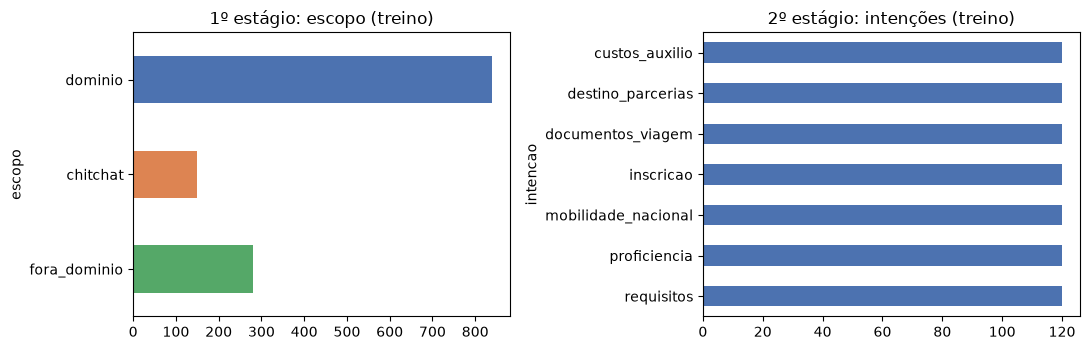

,mean,min,max
intencao,,,
chitchat,7.1,1,18
custos_auxilio,11.2,2,24
destino_parcerias,9.8,3,27
documentos_viagem,12.2,3,26
fora_dominio,9.8,2,30
inscricao,9.8,2,24
mobilidade_nacional,15.4,2,31
proficiencia,10.2,3,24
requisitos,11.3,2,24


,mean,min,max
origem,,,
humano,8.5,1,30
llm,11.2,1,31


chitchat             ['voce', 'foi', 'bom', 'ate', 'bot', 'estou', 'tudo', 'hoje']
custos_auxilio       ['intercambio', 'bolsa', 'auxilio', 'ufms', 'algum', 'despesas', 'quanto', 'financeiro']
destino_parcerias    ['ufms', 'universidades', 'paises', 'intercambio', 'conveniadas', 'instituicoes', 'fazer', 'convenio']
documentos_viagem    ['visto', 'preciso', 'pais', 'passaporte', 'intercambio', 'seguro', 'levar', 'antes']
fora_dominio         ['onde', 'faco', 'preciso', 'pais', 'por', 'curso', 'hoje', 'vida']
inscricao            ['edital', 'intercambio', 'processo', 'inscricao', 'onde', 'prazo', 'quando', 'candidatura']
mobilidade_nacional  ['outra', 'universidade', 'ufms', 'disciplinas', 'materias', 'destino', 'periodo', 'cursar']
proficiencia         ['certificado', 'proficiencia', 'idioma', 'ingles', 'comprovar', 'nivel', 'aceito', 'preciso']
requisitos           ['participar', 'intercambio', 'semestre', 'cra', 'preciso', 'estou', 'vinculo', 'disciplinas']


,texto,origem
92,Qual o valor da bolsa de iniciação científica?,humano
93,Posso me transferir para outro curso da UFMS?,humano
94,Como transfiro meu curso em definitivo para outra universidade,humano
95,Quais documentos são necessários para rematrícula,humano
114,qual cidades são ricas em recursos históricos,humano
121,para qual federal eu posso ir e que seja forte para meu curso?,humano
185,Qual área é responsável pelos estágios dentro da UFMS?,humano
195,como estagiar na ufms?,humano
214,qual universidade e referência no meu curso,humano
1120,Poderia explicar como funciona o processo de transferência entre cursos dent...,llm


In [20]:
from collections import Counter
from chatbot.texto import normalizar

# Distribuição das classes
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
treino["escopo"].value_counts().reindex(CLASSES_ESCOPO).plot.barh(ax=eixos[0], color=CORES[:3])
eixos[0].set_title("1º estágio: escopo (treino)"); eixos[0].invert_yaxis()
treino.loc[treino["escopo"] == "dominio", "intencao"].value_counts().plot.barh(ax=eixos[1], color=CORES[0])
eixos[1].set_title("2º estágio: intenções (treino)"); eixos[1].invert_yaxis()
plt.tight_layout(); plt.show()

# Tamanho das mensagens por classe e por origem
tam = treino.assign(n_palavras=treino["texto"].str.split().str.len())
display(tam.groupby("intencao")["n_palavras"].agg(["mean", "min", "max"]).round(1))
display(tam.groupby("origem")["n_palavras"].agg(["mean", "min", "max"]).round(1))

# Palavras mais frequentes por intenção
STOP = {"que", "como", "para", "pra", "com", "uma", "tem", "posso", "qual", "quais", "sobre", "minha", "meu", "nao", "sao", "ser", "mais"}
for intencao, g in treino.groupby("intencao"):
    c = Counter(p for t in g["texto"] for p in normalizar(t).split() if len(p) > 2 and p not in STOP)
    print(f"{intencao:20s}", [p for p, _ in c.most_common(8)])

# Exemplos de negativos difíceis (fora_dominio com palavras do tema)
fora = treino[treino["intencao"] == "fora_dominio"]
fora[fora["texto"].str.contains("bolsa|edital|inscri|ufms|curso|matr", case=False)][["texto", "origem"]].head(10)


---
## 3. Representações de texto

Fizemos a comparação com 4 representações TF-IDF. Todas são normalizadas antes de serem utilizadas

"TF-IDF palavras" : Considera palavras isoladas e pares de palavras\
"TF-IDF palavras (só unigramas)" : Considera palavras isoladas, sendo um "saco de palavras soltas"\
"TF-IDF sem stopwords" : 1-2 gramas, removendo palavras muito comuns como artigos, preposições e conjunções. Isso antes de formar os pares\
"TF-IDF caracteres" : Considera pedaços de 2 a 5 letras dentro de cada palavra, sendo mais robusto a erros de digitação , variação e abreviação

In [21]:
from chatbot.texto import STOPWORDS

REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    "TF-IDF palavras sem stopwords": lambda: tfidf_palavras(stop_words=STOPWORDS),
    "TF-IDF palavras (só unigramas)": lambda: tfidf_palavras(ngram_range=(1,1)),
}


---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

Adicionamos os classificadores KNN com N=5, Naive Bayes e SVM.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [22]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "K Vizinhos mais próximos (KNN)": lambda: KNeighborsClassifier(n_neighbors= 5, metric="cosine"),
    "Naive Bayes": lambda: BernoulliNB(alpha=1.0),
    "SVM Linear": lambda: SVC(kernel="linear", C=1, probability=True),
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Rede neural (MLP),0.897,0.019,0.913,1.000
1,TF-IDF caracteres,SVM Linear,0.889,0.028,0.911,0.974
2,TF-IDF caracteres,Regressão logística,0.877,0.026,0.902,1.000
3,TF-IDF palavras (só unigramas),Rede neural (MLP),0.876,0.023,0.900,1.000
4,TF-IDF palavras sem stopwords,Rede neural (MLP),0.875,0.025,0.900,1.000
5,TF-IDF palavras (só unigramas),SVM Linear,0.870,0.018,0.898,0.983
6,TF-IDF palavras (só unigramas),Regressão logística,0.866,0.027,0.898,1.000
7,TF-IDF palavras,Rede neural (MLP),0.860,0.022,0.889,1.000
8,TF-IDF palavras sem stopwords,SVM Linear,0.859,0.024,0.891,0.996
9,TF-IDF caracteres,Naive Bayes,0.859,0.040,0.888,0.923


### Comparação

Testamos 6 algoritmos (Regressão Logística, MLP, DT, KNN, Naive Bayes e SVM Linear) com as 4 representações definidas anteriormente, utilizando validação cruzada estratificada de 5 folds no treino.

A representação de **TF-IDF caracteres** foi a que gerou melhor resultado para quase todos os algoritmos. Os que obtiveram melhor desempenho foram MLP (F1 = 0.897), SVM linear (F1 = 0.889) e regressão logística (F1 = 0.877), todos com a representação de caracteres.

### Classificadores escolhidos e modelo de representação

Com base na tabela acima, escolhemos MLP, SVM e Regressão Logística todas com a representação TF-IDF caracteres.


🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [25]:
def curva_validacao(busca, param, titulo, log=True):
    """Curva de validação de um hiperparâmetro, com os demais fixos no melhor valor."""
    res = pd.DataFrame(busca.cv_results_)
    for p, v in busca.best_params_.items():          # fixa os outros parâmetros no melhor valor
        if p != param:
            res = res[res["param_" + p].astype(str) == str(v)]
    res = res.assign(x=res["param_" + param].astype(float)).sort_values("x")

    plt.figure(figsize=(6, 3.8))
    plt.errorbar(res["x"], res["mean_train_score"], yerr=res["std_train_score"], fmt="o-", color=CORES[0], label="treino")
    plt.errorbar(res["x"], res["mean_test_score"], yerr=res["std_test_score"], fmt="s-", color=CORES[3], label="validação (CV)")
    if log:
        plt.xscale("log")
    plt.xlabel(param.split("__")[1]); plt.ylabel("F1 macro"); plt.ylim(0, 1.02)
    plt.title(titulo); plt.legend(); plt.show()


In [26]:
grades_escopo = {
    "Regressão logística": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
        param_grid={"vetorizador__ngram_range": [(2, 4), (2, 5), (3, 6)],
                    "classificador__C": [0.01, 0.1, 1, 10, 100, 1000]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),

    "SVM linear": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", SVC(kernel="linear", probability=True))]),
        param_grid={"vetorizador__ngram_range": [(2, 4), (2, 5)],
                    "classificador__C": [0.01, 0.1, 1, 10, 100]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),

    "Rede neural (MLP)": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()),
                  ("classificador", MLPClassifier(max_iter=600, random_state=RANDOM_STATE))]),
        param_grid={"classificador__hidden_layer_sizes": [(32,), (64,), (128,)],
                    "classificador__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),
}

for nome, busca in grades_escopo.items():
    busca.fit(treino["texto"], treino["escopo"])
    print(f"{nome:22s} {busca.best_params_}  F1 = {busca.best_score_:.3f}")


Regressão logística    {'classificador__C': 100, 'vetorizador__ngram_range': (3, 6)}  F1 = 0.888
SVM linear             {'classificador__C': 1, 'vetorizador__ngram_range': (2, 5)}  F1 = 0.889
Rede neural (MLP)      {'classificador__alpha': 0.001, 'classificador__hidden_layer_sizes': (64,)}  F1 = 0.897


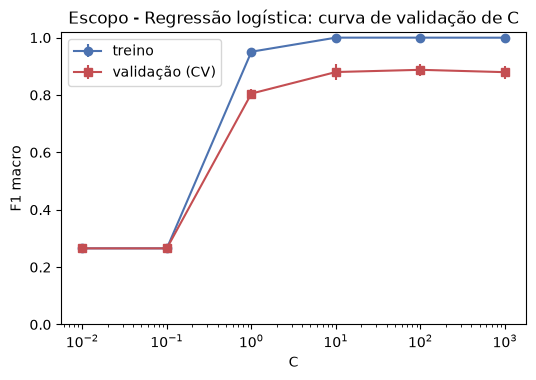

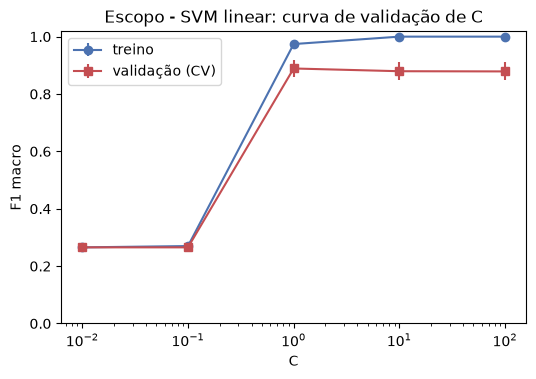

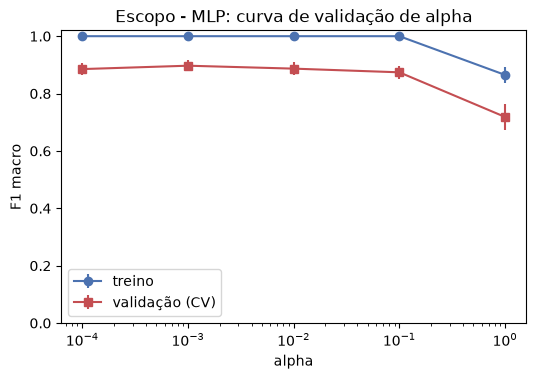

In [27]:
curva_validacao(grades_escopo["Regressão logística"], "classificador__C", "Escopo - Regressão logística: curva de validação de C")
curva_validacao(grades_escopo["SVM linear"], "classificador__C", "Escopo - SVM linear: curva de validação de C")
curva_validacao(grades_escopo["Rede neural (MLP)"], "classificador__alpha", "Escopo - MLP: curva de validação de alpha")


### Ajuste dos Hiperparâmetros

Com o GridSearchCV realizamos o ajuste nos Hiperparâmetros para cada modelo com as seguintes grades: `C` ∈ {0,01 … 1000} e n-gramas (2–4, 2–5, 3–6) para a regressão logística; `C` ∈ {0,01 … 100} para o SVM; `alpha` ∈ {1e-4 … 1} e camada oculta com 32, 64 ou 128 neurônios para a MLP.

As curvas de validação mostram o compromisso entre viés e variância. Com `C` ≤ 0,1, a regularização é tão forte que a regressão logística e o SVM preveem tudo como `dominio` (F1 ≈ 0,27): viés alto. A partir de `C` = 1, o F1 de treino chega a ~1,0 enquanto o de validação se estabiliza em ~0,88: o modelo decora o treino sem ganhar na validação. O SVM teve o melhor resultado em `C` = 1 e foi o único que não chegou a 1,0 no treino (0,974). Na MLP, o desempenho é estável até `alpha` = 0,1 e cai com `alpha` = 1 (viés).


In [ ]:
def taxas_escopo(y, prev):
    fora = y != "dominio"
    return {"falso aceite": ((prev == "dominio") & fora).sum() / fora.sum(),
            "falsa recusa": ((prev != "dominio") & ~fora).sum() / (~fora).sum()}

linhas = []
for nome, busca in grades_escopo.items():
    prev = cross_val_predict(busca.best_estimator_, treino["texto"], treino["escopo"], cv=cv, n_jobs=-1)
    linhas.append({
        "modelo": nome,
        "melhores parâmetros": busca.best_params_,
        "F1 macro (CV)": busca.best_score_,
        "desvio": busca.cv_results_["std_test_score"][busca.best_index_],
        "F1 macro (treino)": busca.cv_results_["mean_train_score"][busca.best_index_],
        **taxas_escopo(treino["escopo"].to_numpy(), prev),
    })

resumo_busca_escopo = pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False)
display(resumo_busca_escopo.style.format({
    "F1 macro (CV)": "{:.3f}", "desvio": "{:.3f}", "F1 macro (treino)": "{:.3f}",
    "falso aceite": "{:.1%}", "falsa recusa": "{:.1%}",
}))

clf_escopo = grades_escopo["Regressão logística"].best_estimator_


,modelo,melhores parâmetros,F1 macro (CV),desvio,F1 macro (treino),falso aceite,falsa recusa
2,Rede neural (MLP),"{'classificador__alpha': 0.001, 'classificador__hidden_layer_sizes': (64,)}",0.897,0.019,1.000,18.6%,2.7%
1,SVM linear,"{'classificador__C': 1, 'vetorizador__ngram_range': (2, 5)}",0.889,0.028,0.974,18.8%,2.4%
0,Regressão logística,"{'classificador__C': 100, 'vetorizador__ngram_range': (3, 6)}",0.888,0.021,1.000,18.4%,3.3%


### Escolha do modelo

Os três finalistas ficaram empatados: a diferença de F1 entre eles (0,888 a 0,897) é menor que o desvio entre os folds (~0,02).

Por isso, desempatamos pelo erro mais grave no nosso domínio, o **falso aceite**. Ele também ficou praticamente empatado: 18,6% na MLP, 19,0% na regressão logística e 20,2% no SVM.

Escolhemos a **regressão logística** com C = 100 e n-gramas de caracteres de 3 a 6, com falso aceite de 19,0% e falsa recusa de 3,2%. Além de empatar com a MLP, ela é determinística, mais rápida, interpretável e fornece probabilidades mais confiáveis.

Como os três modelos aceitam cerca de 19% das mensagens fora do domínio, concluímos que o falso aceite não depende do algoritmo, e sim da falta de negativos difíceis nos dados de treino.

📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

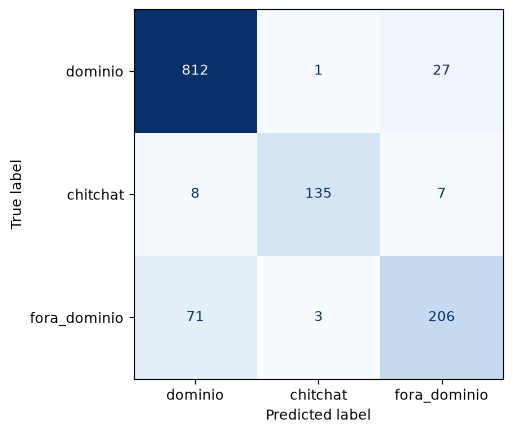

origem                     humano  llm
escopo       previsto                 
chitchat     dominio            1    7
             fora_dominio       3    4
dominio      chitchat           0    1
             fora_dominio      14   13
fora_dominio chitchat           2    1
             dominio           47   24

,texto,escopo,previsto,origem
0,Chat como é ser uma IA?,chitchat,fora_dominio,humano
3,Em qual linguagem de programação tu foi escrito?,chitchat,dominio,humano
6,quem é vc,chitchat,fora_dominio,humano
8,"Gostaria de saber como o chatbot foi criado, e por qual motivo",chitchat,fora_dominio,humano
11,Eu teria direito a moradia?,dominio,fora_dominio,humano
14,Quais seriam meus gastos estimados e receita?,dominio,fora_dominio,humano
16,Se a uf disponibiliza auxílio,dominio,fora_dominio,humano
17,Quais são os benefícios?,dominio,fora_dominio,humano
19,Onde eu me hospedaria.,dominio,fora_dominio,humano
23,Qual é o preço?,dominio,fora_dominio,humano


In [38]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

erros = treino.assign(previsto=prev_cv).query("escopo != previsto")
display(erros.groupby(["escopo", "previsto", "origem"]).size().unstack(fill_value=0)) 
with pd.option_context("display.max_rows", None):
    display(erros[["texto", "escopo", "previsto", "origem"]])       


**Análise dos erros.** Na validação cruzada, o modelo escolhido teve falso aceite de **18,3%**  e falsa recusa de **3,3%**.

A maior parte dos erros são **negativos difíceis previstos como domínio**: perguntas sobre outros assuntos da UFMS com vocabulário parecido com o nosso, como "auxílio permanência", "bolsa permanência estudantil" e "CRA no histórico". Também há chitchat sobre o próprio bot ("quem é vc", "como o chatbot foi criado") previsto como fora do domínio. Por origem, **67** erros são de frases humanas e **50** de frases de LLM.

**Qual erro é mais grave?** No nosso domínio, o **falso aceite**. Um aluno que pergunta sobre auxílio permanência receberia valores de bolsa e prazos de edital de intercâmbio, ou seja, uma informação errada sobre dinheiro e prazos, dada com confiança. Já na falsa recusa o aluno recebe o contato da AGINTER e ainda consegue a informação certa.


---
## 5. Classificador de tema (intenções do domínio)


In [39]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF palavras sem stopwords,Regressão logística,0.949,0.012,0.949,1.000
1,TF-IDF caracteres,Regressão logística,0.946,0.020,0.946,1.000
2,TF-IDF palavras,Rede neural (MLP),0.946,0.007,0.946,1.000
3,TF-IDF caracteres,SVM Linear,0.944,0.018,0.944,0.999
4,TF-IDF palavras sem stopwords,SVM Linear,0.944,0.009,0.944,1.000
5,TF-IDF palavras (só unigramas),Rede neural (MLP),0.942,0.015,0.942,1.000
6,TF-IDF palavras (só unigramas),SVM Linear,0.942,0.018,0.942,0.999
7,TF-IDF palavras (só unigramas),Regressão logística,0.942,0.023,0.942,1.000
8,TF-IDF caracteres,Rede neural (MLP),0.941,0.019,0.940,1.000
9,TF-IDF palavras sem stopwords,Rede neural (MLP),0.940,0.007,0.940,1.000


### Comparação

Usamos os mesmos 6 algoritmos e as 4 representações, com validação cruzada estratificada de 5 folds, só nas 840 frases do domínio, 120 para cada domínio.

O problema de tema é mais fácil que o de escopo: os 12 melhores pares ficaram entre F1 = 0.935 e 0.949, com diferenças menores que o desvio entre folds (0.01–0.02), ou seja, estatisticamente empatados. Regressão logística, MLP e SVM linear foram os melhores com qualquer representação. Naive Bayes e KNN ficaram em torno de 0.90 e a árvore de decisão foi a pior (0.71–0.79), com F1 de treino 1.0 (overfitting).

O melhor resultado foi a regressão logística com palavras sem stopwords (0.949), mas a diferença para os caracteres (0.946) é menor que o desvio. Escolhemos **TF-IDF de caracteres** para os três finalistas, porque é mais robusto a erros de digitação e abreviações, comuns nas frases humanas do teste, e porque é a mesma representação do classificador de escopo.


In [40]:
X_tema, y_tema = treino_dom["texto"], treino_dom["intencao"]

grades_tema = {
    "Regressão logística": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
        param_grid={"vetorizador__ngram_range": [(2, 4), (2, 5), (3, 6)],
                    "classificador__C": [0.01, 0.1, 1, 10, 100, 1000]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),

    "SVM linear": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", SVC(kernel="linear", probability=True))]),
        param_grid={"vetorizador__ngram_range": [(2, 4), (2, 5)],
                    "classificador__C": [0.01, 0.1, 1, 10, 100]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),

    "Rede neural (MLP)": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()),
                  ("classificador", MLPClassifier(max_iter=600, random_state=RANDOM_STATE))]),
        param_grid={"classificador__hidden_layer_sizes": [(32,), (64,), (128,)],
                    "classificador__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),
}

for nome, busca in grades_tema.items():
    busca.fit(X_tema, y_tema)
    print(f"{nome:22s} {busca.best_params_}  F1 = {busca.best_score_:.3f}")


Regressão logística    {'classificador__C': 100, 'vetorizador__ngram_range': (2, 5)}  F1 = 0.947
SVM linear             {'classificador__C': 10, 'vetorizador__ngram_range': (2, 5)}  F1 = 0.944
Rede neural (MLP)      {'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (128,)}  F1 = 0.951


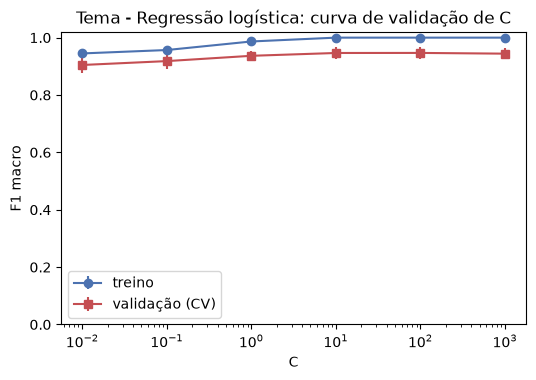

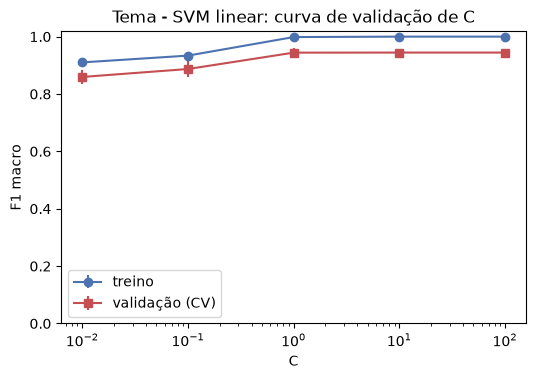

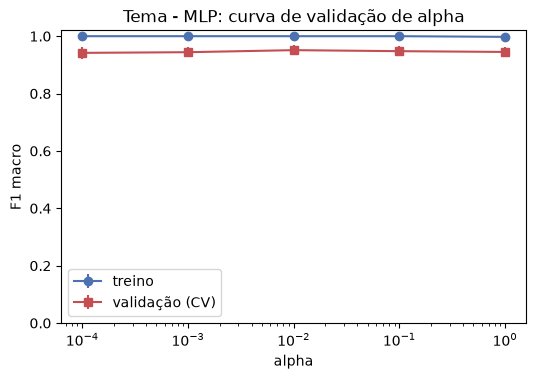

In [41]:
curva_validacao(grades_tema["Regressão logística"], "classificador__C", "Tema - Regressão logística: curva de validação de C")
curva_validacao(grades_tema["SVM linear"], "classificador__C", "Tema - SVM linear: curva de validação de C")
curva_validacao(grades_tema["Rede neural (MLP)"], "classificador__alpha", "Tema - MLP: curva de validação de alpha")


### Ajuste dos hiperparâmetros

Melhores combinações: regressão logística com C = 100 e n-gramas de 2 a 5; SVM linear com C = 10 e n-gramas de 2 a 5; MLP com alpha = 0,01 e 128 neurônios.

Nas curvas de validação, a distância entre treino (1.0) e validação (~0.95) é pequena, então o sobreajuste é moderado.


In [42]:
from sklearn.metrics import log_loss

linhas_tema = []
for nome, busca in grades_tema.items():
    proba = cross_val_predict(busca.best_estimator_, X_tema, y_tema, cv=cv, method="predict_proba", n_jobs=-1)
    classes = np.array(sorted(y_tema.unique()))
    previsto = classes[proba.argmax(axis=1)]
    errou = previsto != y_tema.to_numpy()
    linhas_tema.append({
        "modelo": nome,
        "F1 macro (CV)": busca.best_score_,
        "desvio": busca.cv_results_["std_test_score"][busca.best_index_],
        "F1 macro (treino)": busca.cv_results_["mean_train_score"][busca.best_index_],
        "log loss": log_loss(y_tema, proba, labels=classes),
        "confiança média nos erros": proba.max(axis=1)[errou].mean(),
    })

resumo_busca_tema = pd.DataFrame(linhas_tema).sort_values("F1 macro (CV)", ascending=False)
display(resumo_busca_tema.style.format({c: "{:.3f}" for c in resumo_busca_tema.columns if c != "modelo"}))

# escolham o modelo e justifiquem no markdown
clf_tema = grades_tema["Regressão logística"].best_estimator_


,modelo,F1 macro (CV),desvio,F1 macro (treino),log loss,confiança média nos erros
2,Rede neural (MLP),0.951,0.018,1.000,0.178,0.643
0,Regressão logística,0.947,0.019,1.000,0.188,0.586
1,SVM linear,0.944,0.014,1.000,0.213,0.535


### Escolha do modelo

Os três finalistas empataram no F1 macro (0.944 a 0.951; desvio ~0.015–0.019). Como este classificador define o limiar de confiança, desempatamos pela qualidade das probabilidades:

* **log loss**: MLP 0.178, regressão logística 0.188, SVM 0.213;
* **confiança média nos erros**: SVM 0.535, regressão logística 0.586, MLP 0.643.

A MLP tem as probabilidades mais bem calibradas, mas erra com mais certeza. O SVM erra com mais dúvida, mas tem o pior log loss. Escolhemos a **regressão logística (C = 100, n-gramas de caracteres de 2 a 5)**, que fica no meio-termo nos dois critérios, é determinística e é o mesmo algoritmo do classificador de escopo.


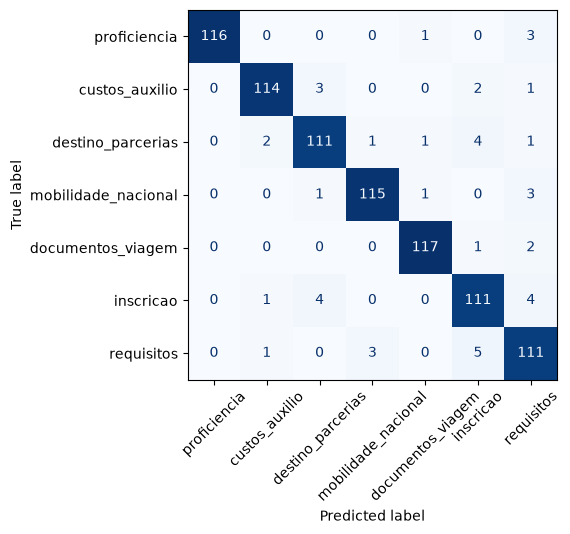

                     precision    recall  f1-score   support

     custos_auxilio       0.97      0.95      0.96       120
  destino_parcerias       0.93      0.93      0.93       120
  documentos_viagem       0.97      0.97      0.97       120
          inscricao       0.90      0.93      0.91       120
mobilidade_nacional       0.97      0.96      0.96       120
       proficiencia       1.00      0.97      0.98       120
         requisitos       0.89      0.93      0.91       120

           accuracy                           0.95       840
          macro avg       0.95      0.95      0.95       840
       weighted avg       0.95      0.95      0.95       840



In [43]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

### Confusões entre intenções

Na validação cruzada, a regressão logística teve F1 macro de 0.95. As intenções mais fáceis foram `proficiencia` (F1 = 0.98) e `documentos_viagem` (0.97). As mais difíceis foram `inscricao` e `requisitos` (0.91) que por serem de uma natureza essencialmente próxima acaba causando isso e `destino_parcerias` (0.93).

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [ ]:
# 🔨 TODO

---
## 7. Salvar os modelos finais

In [ ]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [ ]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "TODO: uma pergunta do seu domínio", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

In [ ]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [ ]:
!{sys.executable} scripts/verificar_entrega.py